In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt

# %matplotlib widget
# from mpl_toolkits.mplot3d import Axes3D

In [ ]:
files = ["run1.txt", "run2.txt", "run3.txt", "run4.txt", "run5.txt", "run6.txt"]

for file in files:
    with open(file, "r") as my_file:
        data = my_file.read()

    new_data = data.replace('\n', ',').replace('[', '').replace(']', '').replace(' ', '')
    list_data = new_data.split(",")
    max_idx = len(list_data)
    arr_data = np.array(list_data, dtype=np.float32)
    # max_idx = 50

    arr1 = arr_data[0:max_idx:3]
    arr2 = arr_data[1:max_idx:3]
    arr3 = arr_data[2:max_idx:3]

    '''Recalculate headings'''
    # asize = arr1.size
    # arr3 = np.zeros(asize)
    # for i in range(asize):
    #     heading = math.atan2(arr1[i], arr2[i]) * 180 / math.pi
    #     if heading<0: heading += 360
    #     arr3[i] = heading
    
    # print(arr3.size, arr3[5:10], type(arr3[2]))
    plt.plot(arr3)
    plt.xlabel('Reading Index')
    plt.ylabel('Degrees')
    plt.show()

In [ ]:
files = ["run6.txt"]

for file in files:
    with open(file, "r") as my_file:
        data = my_file.read()

    new_data = data.replace('\n', ',').replace('[', '').replace(']', '').replace(' ', '')
    list_data = new_data.split(",")
    max_idx = len(list_data)
    arr_data = np.array(list_data, dtype=np.float32)
    arr1 = arr_data[0:max_idx:3]
    arr2 = arr_data[1:max_idx:3]
    arr3 = arr_data[2:max_idx:3]
    plt.plot(arr1)
    plt.xlabel('Reading Index')
    plt.ylabel('y uTesla')
    plt.show()
    plt.plot(arr2)
    plt.xlabel('Reading Index')
    plt.ylabel('x uTesla')
    plt.show()
    plt.plot(arr3)
    plt.xlabel('Reading Index')
    plt.ylabel('Degrees')
    plt.show()

In [5]:
def define_lims(v1, v2):
    v1l = [np.max(v1), np.min(v1)]
    v2l = [np.max(v2), np.min(v2)]
    val1_diff = v1l[0]-v1l[1]
    val2_diff = v2l[0]-v2l[1]
    if val1_diff > val2_diff:
        fix = (val1_diff-val2_diff)/2
        v2l[0] += fix
        v2l[1] -= fix
    else:
        fix = (val2_diff-val1_diff)/2
        v1l[0] += fix
        v1l[1] -= fix
    return v1l, v2l

def define_lims3(v1, v2, v3):
    lims = [[np.max(v1), np.min(v1)], [np.max(v2), np.min(v2)], [np.max(v3), np.min(v3)]]
    llims = np.array([np.min(v1), np.min(v2), np.min(v3)])
    hlims = np.array([np.max(v1), np.max(v2), np.max(v3)])
    diffs = np.abs(hlims-llims)
    maxl = np.max(diffs)
    for i in range(3):
        if diffs[i] != maxl:
            fix = (maxl-diffs[i])/2
            lims[i][0] += fix
            lims[i][1] -= fix
    return lims
    
def find_minmax(txtfile):
    with open(txtfile, "r") as my_file:
        data = my_file.read()
    new_data = data.replace('\n', ' ').replace('\t', ' ')
    list_data = new_data.split(" ")
    arr_data = np.array(list_data, dtype=np.float32)
    print(np.max(arr_data), np.min(arr_data))

def plot2d(val1, val2):
    val1limits, val2limits = define_lims(val1, val2)
    plt.figure(figsize=(6,6))
    plt.xlim(val1limits[1], val1limits[0])
    plt.ylim(val2limits[1], val2limits[0])
    plt.plot(val1, val2, 'o-')
    plt.show()

def plot3d(val1, val2, val3):
    axislims = define_lims3(val1, val2, val3)
    fig = plt.figure(figsize=(6,6))
    ax = fig.add_subplot(111, projection='3d')
    # ax.scatter(val1, val2, val3, zdir='z', s=20, c='b',rasterized=True)
    
    # ax = Axes3D(fig)
    ax.scatter(val1, val2, val3, color='green')
    ax.set_title("3D plot")
    
    # Display the sub-plots
    # ax.scatter(val1, val2, color='r')
    # ax.scatter(val2, val3, color='g')
    # ax.scatter(val3, val1, color='b')
    
    ax.axes.set_xlim3d(axislims[0][1], axislims[0][0]) 
    ax.axes.set_ylim3d(axislims[1][1], axislims[1][0])
    ax.axes.set_zlim3d(axislims[2][1], axislims[2][0])
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    plt.show()

def parsefile(filename):
    with open(filename, "r") as my_file:
        data = my_file.read()
    new_data = data.replace('\n', ' ').replace('\t', ' ')
    list_data = new_data.split(" ")
    max_idx = len(list_data)
    arr_data = np.array(list_data, dtype=np.float32)
    arr1 = arr_data[0:max_idx:3]
    arr2 = arr_data[1:max_idx:3]
    arr3 = arr_data[2:max_idx:3]
    return arr1, arr2, arr3

def data_properties(d_array):
    print(f"Max: {np.max(d_array)}, Min: {np.min(d_array)}, Median: {np.median(d_array)}, Mean: {np.mean(d_array)}, Std: {np.std(d_array)}")


    

In [48]:
cfiles = ["calibdata4_circles.txt", "testdata_lawn.txt", "testdata_raw.txt", "idealdata.txt", "calibdata3.txt", 
          "data_lawn.txt"]
file = cfiles[5]
find_minmax(file)

47.25 -23.125


In [53]:
def to_sphere(ex, ey, ez, a, b, c):
    # sfact = 1 / math.pow((a*b*c), 2/3)
    # smat = np.array([ [b*c, 0, 0], [0, a*c, 0], [0, 0, a*b] ])
    # epoints = np.column_stack((ex, ey, ez))
    # with open("sphere.txt", "w") as my_file:
    #     for elm in epoints:
    #         mx, my, mz = np.dot(elm, sfact*smat)
    #         my_file.write(f"{mx}\t{my}\t{mz}\n")
    sx, sy, sz = parsefile("sphere.txt")
    plot2d(sy,sz)
    # return spoints

Max: 5.125, Min: -77.875, Median: -31.125, Mean: -35.09306716918945, Std: 27.027362823486328
Max: 15.0, Min: -28.25, Median: -4.5, Mean: -5.532390594482422, Std: 14.30962085723877
Max: 8.8125, Min: -103.375, Median: -40.9375, Mean: -45.55394744873047, Std: 38.1418571472168


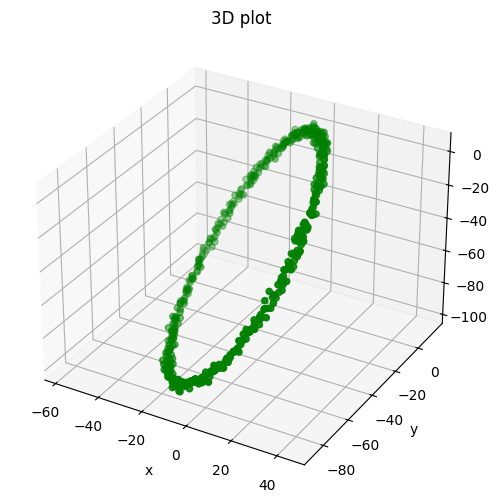

Max: 27.5625, Min: -23.125, Median: 4.46875, Mean: 3.6592133045196533, Std: 15.56031608581543
Max: 36.9375, Min: -15.75, Median: 12.25, Mean: 10.980334281921387, Std: 15.254063606262207
Max: 47.25, Min: 29.375, Median: 39.78125, Mean: 39.62580871582031, Std: 4.037633419036865


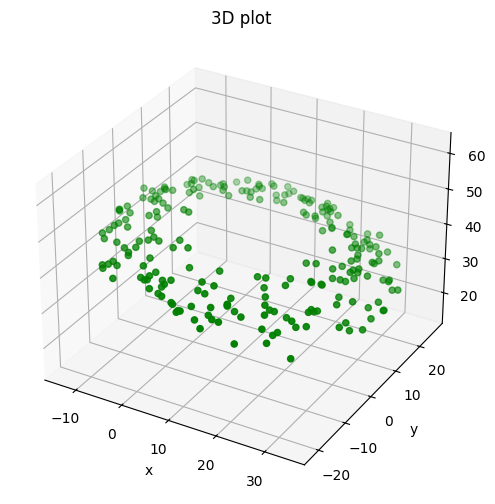

In [51]:
'''plot calibration data'''

cfiles = ["calibdata4_circles.txt", "data_lawn.txt"]
plottype = '3d'

for file in cfiles:
    vx, vy, vz = parsefile(file)
    data_properties(vx)
    data_properties(vy)
    data_properties(vz)
    if plottype == '2d':
        plot2d(vx, vy)
        to_sphere(vx,vy,vz, 3.1749684, 68.15953771, 16.18773926)
    else:
        plot3d(vy, vx, vz)

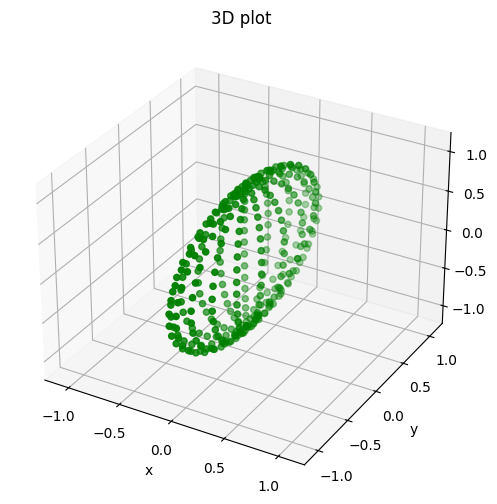

In [14]:
'''plot calibrated/test run data'''
def fit_ellipse(x, y):
    points = np.column_stack((x, y))
    points = np.array(points, dtype='f')
    ellipse = cv2.fitEllipse(points)
    # print(ellipse)
    (center, axes, angle) = ellipse
    print(f"Center at: {center}, Axes lengths: {axes}, Rotated: {angle}")
    
# pfiles = ["pdata_calib4.txt", "pdata_lawn.txt"]
pfiles = ["idealdata.txt"]
plottype = '3d'

for file in pfiles:
    vx, vy, vz = parsefile(file)
    if plottype == '2d':
        fit_ellipse(vy,vz)
        plot2d(vx, vz)        
    else:
        plot3d(vy, vx, vz)

In [38]:
''' create processed data'''

# s_offset = [[4.418964, -0.262379, -2.005191], [-0.262379, 5.583431, -0.436255], [-2.005191, -0.436255, 3.040697]]
# h_offset = [-37.157983, -6.833091, -48.307929]

# s_offset = [[-3.875346, 0.037126, -1.828816], [0.037126, -5.446044, -0.287859], [-1.828816, -0.287859, -4.195969]]
# h_offset = [-720.683027, 1084.572524, -1190.567618]

# s_offset = [[2.324329, -0.005460, -0.060285], [-0.005460, 2.456983, -0.012367], [-0.060285, -0.012367, 2.489272]]
# h_offset = [-1128.978454, 1124.907735, -1014.810137]

# data_lawn 47.25
# s_offset = [[1.432516, -0.043742, 0.005637], [-0.043742, 1.420326, 0.144995], [0.005637, 0.144995, 1.943311]]
# h_offset = [2.548150, 6.794198, 22.233851]

# calibdata4_circles -103.375
# s_offset = [[-4.418964, 0.262379, 2.005191], [0.262379, -5.583431, 0.436255], [2.005191, 0.436255, -3.040697]]
# 49 norm
s_offset = [[2.094600, -0.124368, -0.950465], [-0.124368, 2.646560, -0.206786], [-0.950465, -0.206786, 1.441298]]
h_offset = [-37.157983, -6.833091, -48.307929]

hard_iron = np.array(h_offset)
soft_iron = np.array(s_offset)

def apply_iron_offsets(magneto):
    A = np.array(magneto)
    # return np.matmul(A-hard_iron, soft_iron)
    return np.dot(A-hard_iron,soft_iron)

file = "calibdata4_circles.txt"
pfile = "new_data.txt"

vx, vy, vz = parsefile(file)

with open(pfile, "w") as my_file:
    for i in range(arr1.size):
        mx, my, mz = apply_iron_offsets([arr1[i], arr2[i], arr3[i]])
        my_file.write(f"{mx}\t{my}\t{mz}\n")

In [12]:
# with open("idealdata.txt", "w") as my_file:
#     for i in range(x.size):
#         my_file.write(f"{x[i]}\t{y[i]}\t{z[i]}\n")

# s_offset = [[1.200078,0,0], [0,1.946490,0], [0,0,1.438712]]
# h_offset = [0.017933, 0, 0]

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import spatial

def change_center(dx, dy, dz, center):
    tx = dx - center[0]
    ty = dy - center[1]
    tz = dz - center[2]
    return tx, ty, tz

def rotate_ellipse(dx, dy, dz, angle):
    theta = np.radians(angle)
    cos_theta, sin_theta = round(np.cos(theta),3), round(np.sin(theta),3)
    rotation_matrix = np.array([
        [cos_theta, -sin_theta, 0],
        [sin_theta, cos_theta, 0],
        [0, 0, 1]
    ])
    data = np.column_stack((dx, dy, dz))
    n = len(dx)
    for i in range(n):
        data[i] = np.dot(rotation_matrix, data[i].T).T
    return data[:,0], data[:,1], data[:,2]

def flat_ellipse(dx, dy, dz, angle):
    theta = np.radians(angle)
    cos_theta, sin_theta = round(np.cos(theta),3), round(np.sin(theta),3)
    # rotation_matrix_y = np.array([
    #     [cos_theta, 0, sin_theta],
    #     [0, 1, 0],
    #     [-sin_theta, 0, cos_theta]
    # ])
    rotation_matrix = np.array([
        [1, 0, 0],
        [0, cos_theta, -sin_theta],
        [0, sin_theta, cos_theta]
    ])
    data = np.column_stack((dx, dy, dz))
    n = len(dx)
    for i in range(n):
        data[i] = np.dot(rotation_matrix, data[i].T).T
    return data[:,0], data[:,1], data[:,2]

def single_transform(dx, dy, dz, theta, phi):
    theta = np.radians(theta)
    phi = np.radians(phi)
    rot_mat = np.array([
    [           np.cos(phi),           -np.sin(phi),           0],
    [np.cos(theta)*np.sin(phi), np.cos(phi)*np.cos(theta), -np.sin(theta)],
    [np.sin(phi)*np.sin(theta), np.cos(phi)*np.sin(theta),  np.cos(theta)]
                       ])
    data = np.column_stack((dx, dy, dz))
    n = len(dx)
    for i in range(n):
        data[i] = np.dot(rot_mat, data[i].T).T
    return data[:,0], data[:,1], data[:,2]

def to_circle(ex, ey, axes, mmax):
    major_axis, minor_axis = axes
    # scale_factor = major_axis / minor_axis
    # normalized_x = ex / scale_factor
    # normalized_y = ey
    norm = mmax*2
    scale_factor1 = major_axis / norm
    scale_factor2 = minor_axis / norm
    normalized_x = ex / scale_factor1
    normalized_y = ey / scale_factor2
    return normalized_x, normalized_y

def find_closest(cx, cy, circle_points):
    distance, index = spatial.KDTree(circle_points).query([cx, cy])
    new_pt = circle_points[index]
    return new_pt

def make_circle(ax, c_x, c_y):
    theta = np.linspace(0, 2*np.pi, 500)
    l = ax
    x = l * np.cos(theta)
    y = l * np.sin(theta)
    circle_points = np.column_stack((x,y))
    given_points = np.column_stack((c_x,c_y))
    # print(c_x.size)
    n = c_x.size
    for i in range(n):
        pt = given_points[i]
        given_points[i] = find_closest(pt[0], pt[1], circle_points)
    return given_points[:,0], given_points[:,1]
    

Center: (-16.396305084228516, 24.100204467773438)
Axes: (51.355064392089844, 56.90375518798828)
Angle: 73.76220703125

Axes: (91.67245483398438, 100.5318374633789)


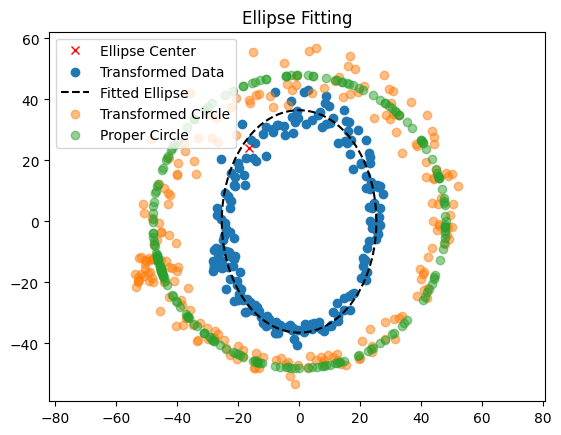

In [30]:
# 28.3522° N, 77.3278° E 217 m

# cfiles = ["calibdata4_circles.txt"]
cfiles = ["backyard_data.txt"]

# cfiles = ["testdata_lawn.txt"]
# cfiles = ["calibdata2.txt"]
# cfiles = ["data_lawn_table3.txt"]
# cfiles = ["calibdata3.txt"]

# cfiles = ["data_lawn_new_table.txt"]
# center_3d = [14.9385, 7.5867, 64.4245]
# plane_angle = 67.0684


center_3d = [-16.3694, 24.4040, -29.3979]
plane_angle = 38.9686
norm = 48

for file in cfiles:
    # read data from file
    mx, my, mz = parsefile(file)
    mxy = np.column_stack((mx, my))
    points = np.array(mxy, dtype='f')

    # fit data to an ellipse
    ellipse = cv2.fitEllipse(points)
    (center, axes, angle) = ellipse
    print(f"Center: {center}")
    print(f"Axes: {axes}")
    print(f"Angle: {angle}")

    # plot original data
    # plt.scatter(mx, my, label='Original Data')
    plt.plot(ellipse[0][0], ellipse[0][1], 'rx', label='Ellipse Center')
    # fig = plt.figure(figsize=(6,6))

    # translate and rotate data, then plot it
    # mx, my = change_center(mx, my, center)
    # ([-33.4653075646861, -4.52844071549064, -37.4985532392603])
    mx, my, mz = change_center(mx, my, mz, center_3d)

    # plt.scatter(my, mz, label='Flatten', alpha=0.5, marker='+')
    
    # mx, my, mz = rotate_ellipse(mx, my, mz, -angle)
    # mx, my, mz = flat_ellipse(mx, my, mz, plane_angle)

    mx, my, mz = single_transform(mx, my, mz, plane_angle, -angle)
    
    mxy = np.column_stack((mx, my))
    points = np.array(mxy, dtype='f')
    ellipse = cv2.fitEllipse(points)
    (center, axes, angle) = ellipse

    plt.scatter(mx, my, label='Transformed Data')
    
    # plot the ellipse that was fitted to the data
    theta = np.linspace(0, 2*np.pi, 100)
    a, b = axes[0]/2, axes[1]/2
    x = a * np.cos(theta)
    y = b * np.sin(theta)
    epoints = np.column_stack((x,y))
    plt.plot(x, y, label='Fitted Ellipse', linestyle='--', color='black')

    # change ellipse to circle and see the plotted results
    circ_x, circ_y = to_circle(mx, my, axes, norm)
    plt.scatter(circ_x, circ_y, label='Transformed Circle', alpha=0.5, marker='o')
    datapoints = np.column_stack((circ_x, circ_y))
    datapoints = np.array(datapoints, dtype='f')
    ellipse2 = cv2.fitEllipse(datapoints)
    (center, axes, angle) = ellipse2
    print(f"\nAxes: {axes}")

    # map the point to points on the circle
    cx, cy = make_circle(norm, circ_x, circ_y)
    plt.scatter(cx, cy, label='Proper Circle', alpha=0.5, marker='o')

    plt.title('Ellipse Fitting')
    plt.legend()
    plt.axis('equal')
    plt.show()


Center: (-6.340773105621338, -0.3038366436958313)
Axes: (42.0596809387207, 53.71565628051758)


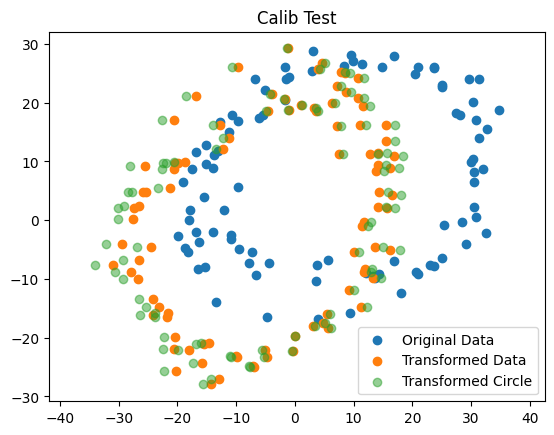

In [58]:
''' apply parameters to new data '''

center = (3.124173641204834, 10.210946083068848)
axes = (43.39207458496094, 47.614315032958984)
angle = 143.2361297607422

mx, my, mz = parsefile("data_lawn1.txt")
plt.scatter(mx, my, label='Original Data')
mx, my = change_center(mx, my, center)
mx, my, mz = rotate_ellipse(mx, my, mz, -angle)
plt.scatter(mx, my, label='Transformed Data')
circ_x, circ_y = to_circle(mx, my, axes)
plt.scatter(circ_x, circ_y, label='Transformed Circle', alpha=0.5, marker='o')

datapoints = np.column_stack((circ_x, circ_y))
datapoints = np.array(datapoints, dtype='f')
ellipse2 = cv2.fitEllipse(datapoints)
(center, axes, angle) = ellipse2
print(f"Center: {center}")
print(f"Axes: {axes}")

plt.title('Calib Test')
plt.legend()
plt.axis('equal')
plt.show()

<class 'list'> 2
[10.4420372  51.96117646]


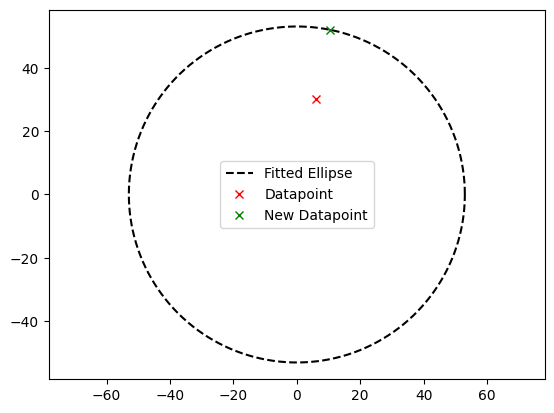

In [95]:
''' move to nearest point on circle '''
from scipy import spatial

theta = np.linspace(0, 2*np.pi, 500)
l = 53
x = l * np.cos(theta)
y = l * np.sin(theta)
epoints = np.column_stack((x,y))
plt.plot(x, y, label='Fitted Ellipse', linestyle='--', color='black')

pt = [6, 30]
print(type(pt), len(pt))
plt.plot(pt[0], pt[1], 'rx', label='Datapoint')
distance, index = spatial.KDTree(epoints).query(pt)
new_pt = epoints[index]
print(new_pt)
plt.plot(new_pt[0], new_pt[1], 'gx', label='New Datapoint')

plt.legend()
plt.axis('equal')
plt.show()

In [65]:
'''
use matlab in python at
https://mscipio.github.io/post/matlab-from-python/
'''

# import matlab.engine
# eng = matlab.engine.start_matlab()

# eng.exit

' use matlab in python '